# 02 · Exploratory data analysis

Questions this notebook answers before any model is trained:

1. What do falls and FoG look like in the common (V, AP, ML, |a|) representation?
2. How different are the two domains before any learning: amplitude, spectrum, channel coupling?
3. Is the FoG signature visible at the trunk at all, or only at the ankle?
4. What does robust scaling do to the cross-domain gap?

Every figure is written to `results/figures` as PNG and PDF.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import signal, stats

sys.path.insert(0, str(Path.cwd().parent))
from src import config as C
from src import data as D
from src.plotting import save, set_style
from src.transforms import RobustScaler

set_style()
X_sis = np.load(C.DATA_PROCESSED / "sisfall_X_g.npy")
X_dap = np.load(C.DATA_PROCESSED / "daphnet_X_g.npy")
meta_sis = pd.read_csv(C.DATA_PROCESSED / "sisfall_meta.csv")
meta_dap = pd.read_csv(C.DATA_PROCESSED / "daphnet_meta.csv")
scalers = json.load(open(C.DATA_PROCESSED / "scalers.json"))
summary = pd.read_csv(C.METRICS / "dataset_summary.csv", index_col=0)
summary

,negatives,positives,subjects,positive %,domain
train,44705,4877,25,9.84,SisFall
val,8738,229,5,2.55,SisFall
test,14173,381,8,2.62,SisFall
target,15676,1734,10,9.96,Daphnet


In [2]:
GROUPS = {
    "SisFall ADL": (X_sis, (meta_sis.label == 0) & meta_sis.coarse),
    "SisFall fall": (X_sis, (meta_sis.label == 1) & meta_sis.coarse),
    "Daphnet walk": (X_dap, meta_dap.label == 0),
    "Daphnet FoG": (X_dap, meta_dap.label == 1),
}
GCOL = {"SisFall ADL": "#8DA0CB", "SisFall fall": "#E78AC3",
        "Daphnet walk": "#66C2A5", "Daphnet FoG": "#FC8D62"}
for k, (X, m) in GROUPS.items():
    print(f"{k:14s} {int(m.sum()):7d} windows")

SisFall ADL      67616 windows
SisFall fall      1827 windows
Daphnet walk     15676 windows
Daphnet FoG       1734 windows


## 1. Processing pipeline

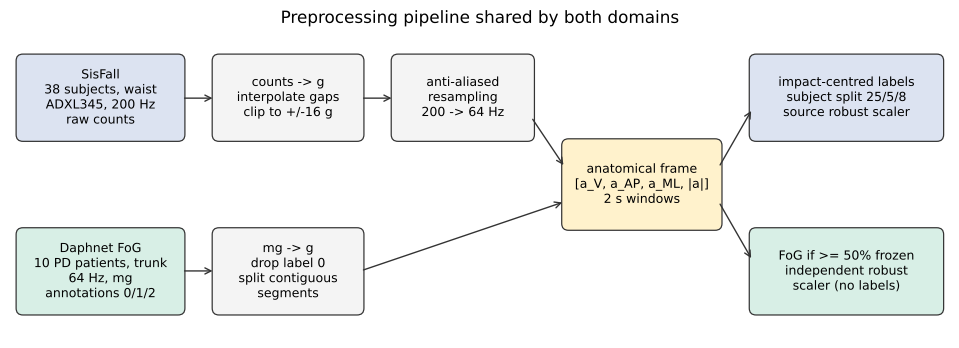

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.set_xlim(0, 11)
ax.set_ylim(0, 3.6)
ax.axis("off")


def box(x, y, w, h, text, fc):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.08",
                                         fc=fc, ec="#333333", lw=0.8))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8.2)


def arrow(x0, y0, x1, y1):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", lw=0.9, color="#333333"))


box(0.1, 2.35, 1.9, 0.95, "SisFall\n38 subjects, waist\nADXL345, 200 Hz\nraw counts", "#DCE3F1")
box(0.1, 0.3, 1.9, 0.95, "Daphnet FoG\n10 PD patients, trunk\n64 Hz, mg\nannotations 0/1/2", "#D8EFE6")
box(2.4, 2.35, 1.7, 0.95, "counts -> g\ninterpolate gaps\nclip to +/-16 g", "#F4F4F4")
box(2.4, 0.3, 1.7, 0.95, "mg -> g\ndrop label 0\nsplit contiguous\nsegments", "#F4F4F4")
box(4.5, 2.35, 1.6, 0.95, "anti-aliased\nresampling\n200 -> 64 Hz", "#F4F4F4")
box(6.5, 1.3, 1.8, 1.0, "anatomical frame\n[a_V, a_AP, a_ML, |a|]\n2 s windows", "#FFF2CC")
box(8.7, 2.35, 2.2, 0.95, "impact-centred labels\nsubject split 25/5/8\nsource robust scaler", "#DCE3F1")
box(8.7, 0.3, 2.2, 0.95, "FoG if >= 50% frozen\nindependent robust\nscaler (no labels)", "#D8EFE6")
arrow(2.0, 2.82, 2.4, 2.82)
arrow(2.0, 0.78, 2.4, 0.78)
arrow(4.1, 2.82, 4.5, 2.82)
arrow(6.1, 2.6, 6.5, 2.0)
arrow(4.1, 0.78, 6.5, 1.6)
arrow(8.3, 2.0, 8.7, 2.7)
arrow(8.3, 1.6, 8.7, 0.9)
ax.set_title("Preprocessing pipeline shared by both domains", fontsize=11)
save(fig, "fig01_pipeline")

## 2. Class balance

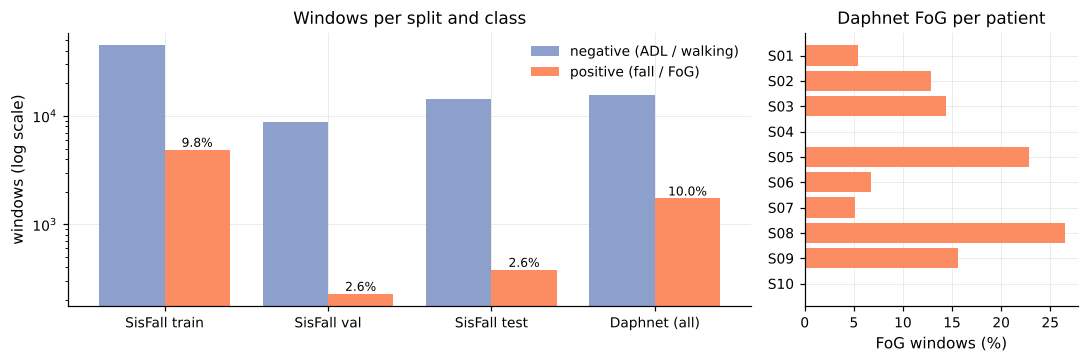

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [3, 1.2]})
s = summary.copy()
labels = ["SisFall train", "SisFall val", "SisFall test", "Daphnet (all)"]
neg, pos = s["negatives"].values, s["positives"].values
x = np.arange(len(labels))
axes[0].bar(x - 0.2, neg, 0.4, label="negative (ADL / walking)", color="#8DA0CB")
axes[0].bar(x + 0.2, pos, 0.4, label="positive (fall / FoG)", color="#FC8D62")
for i in range(len(labels)):
    axes[0].text(x[i] + 0.2, pos[i], f"{100 * pos[i] / (pos[i] + neg[i]):.1f}%", ha="center",
                 va="bottom", fontsize=8)
axes[0].set_xticks(x, labels)
axes[0].set_yscale("log")
axes[0].set_ylabel("windows (log scale)")
axes[0].legend(frameon=False, loc="upper right")
axes[0].set_title("Windows per split and class")

per_subj = meta_dap.groupby("subject").label.mean() * 100
axes[1].barh(per_subj.index, per_subj.values, color="#FC8D62")
axes[1].invert_yaxis()
axes[1].set_xlabel("FoG windows (%)")
axes[1].set_title("Daphnet FoG per patient")
fig.tight_layout()
save(fig, "fig02_class_balance")

In [5]:
dur = meta_sis[meta_sis.coarse].groupby(["group", "is_fall_trial"]).size().unstack() * C.STRIDE_SEC / 3600
print("SisFall hours on the 1 s grid (approximate):")
print(dur.round(2))
print("\nSisFall subjects contributing fall windows:",
      sorted(meta_sis.loc[meta_sis.label == 1, "subject"].unique()))

SisFall hours on the 1 s grid (approximate):
is_fall_trial  False  True 
group                      
Elderly         4.79   0.23
Young           8.99   5.28

SisFall subjects contributing fall windows: ['SA01', 'SA02', 'SA03', 'SA04', 'SA05', 'SA06', 'SA07', 'SA08', 'SA09', 'SA10', 'SA11', 'SA12', 'SA13', 'SA14', 'SA15', 'SA16', 'SA17', 'SA18', 'SA19', 'SA20', 'SA21', 'SA22', 'SA23', 'SE06']


## 3. Axis identification check

The anatomical frame is derived from the data in notebook 01. If the mapping is right, walking
should show ~+1 g on V only, and the post-fall rest should load AP for forward/backward falls and
ML for lateral falls.

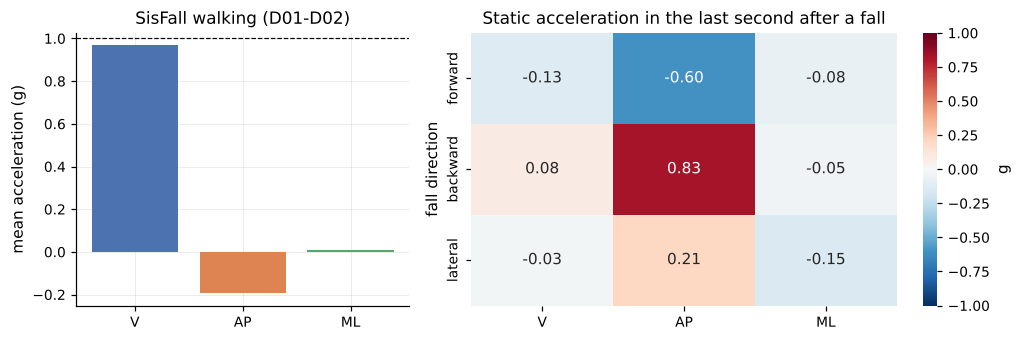

,V,AP,ML
direction,,,
forward,-0.13,-0.60,-0.08
backward,0.08,0.83,-0.05
lateral,-0.03,0.21,-0.15


In [6]:
FALL_DIRECTION = {"F01": "forward", "F02": "backward", "F03": "lateral", "F04": "forward",
                  "F05": "forward", "F08": "forward", "F09": "lateral", "F10": "forward",
                  "F11": "backward", "F12": "lateral", "F13": "forward", "F14": "backward",
                  "F15": "lateral"}
fall_files = meta_sis[meta_sis.is_fall_trial & meta_sis.coarse].copy()
last = fall_files.sort_values("start").groupby("file").tail(1)
last = last[last.activity.isin(FALL_DIRECTION)]
rest = pd.DataFrame(X_sis[last.index.values][:, -C.FS:, :3].mean(axis=1), columns=["V", "AP", "ML"])
rest["direction"] = last.activity.map(FALL_DIRECTION).values
walk = meta_sis[meta_sis.activity.isin(["D01", "D02"]) & meta_sis.coarse]
walk_mean = X_sis[walk.index.values][:, :, :3].mean(axis=(0, 1))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar(["V", "AP", "ML"], walk_mean, color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].axhline(1, ls="--", c="k", lw=0.8)
axes[0].set_ylabel("mean acceleration (g)")
axes[0].set_title("SisFall walking (D01-D02)")
order = ["forward", "backward", "lateral"]
hm = rest.groupby("direction")[["V", "AP", "ML"]].mean().loc[order]
sns.heatmap(hm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1],
            cbar_kws={"label": "g"})
axes[1].set_title("Static acceleration in the last second after a fall")
axes[1].set_ylabel("fall direction")
fig.tight_layout()
save(fig, "fig03_axis_identification")
hm.round(2)

## 4. Signal morphology

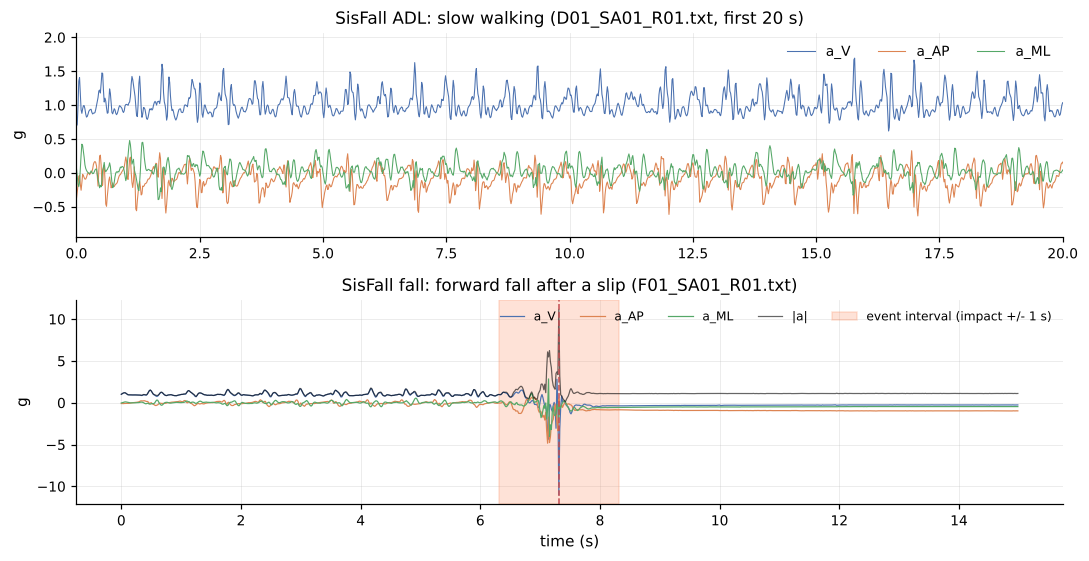

In [7]:
SIS_MAP = {k: tuple(v) for k, v in scalers["sisfall_axis_map"].items()}
sis_idx = D.index_sisfall(C.DATA_RAW / "sisfall").set_index("file")


def load_trial(file):
    """Re-run the notebook-01 chain on one raw file. Windows cannot be stitched back
    together for fall trials because the ambiguous ones were dropped."""
    raw = D.parse_sisfall_file(sis_idx.loc[file, "path"])[:, :3] * C.ADXL345_G_PER_COUNT
    acc = D.resample_to(np.clip(D.fill_missing(raw), -16, 16), C.SISFALL_FS, C.FS)
    return D.to_frame(acc, SIS_MAP)


rng = np.random.default_rng(3)
f_fall = "F01_SA01_R01.txt"
f_walk = "D01_SA01_R01.txt"
sig_fall = load_trial(f_fall)
sig_walk = load_trial(f_walk)
rows_fall = meta_sis[meta_sis.file == f_fall]

fig, axes = plt.subplots(2, 1, figsize=(10, 5.2), sharey=False)
t = np.arange(len(sig_walk)) / C.FS
for k, (name, col) in enumerate(zip(["a_V", "a_AP", "a_ML"], ["#4C72B0", "#DD8452", "#55A868"])):
    axes[0].plot(t, sig_walk[:, k], lw=0.7, color=col, label=name)
axes[0].set_xlim(0, 20)
axes[0].set_title(f"SisFall ADL: slow walking ({f_walk}, first 20 s)")
axes[0].set_ylabel("g")
axes[0].legend(ncol=3, frameon=False, loc="upper right")
t = np.arange(len(sig_fall)) / C.FS
for k, (name, col) in enumerate(zip(["a_V", "a_AP", "a_ML"], ["#4C72B0", "#DD8452", "#55A868"])):
    axes[1].plot(t, sig_fall[:, k], lw=0.8, color=col, label=name)
axes[1].plot(t, sig_fall[:, 3], lw=0.8, color="k", alpha=0.6, label="|a|")
peak = rows_fall.peak.iloc[0] / C.FS
axes[1].axvspan(peak - C.FALL_HALF_EVENT, peak + C.FALL_HALF_EVENT, color="#FC8D62", alpha=0.25,
                label="event interval (impact +/- 1 s)")
axes[1].axvline(peak, color="#C44E52", lw=1, ls="--")
axes[1].set_title(f"SisFall fall: forward fall after a slip ({f_fall})")
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("g")
axes[1].legend(ncol=5, frameon=False, loc="upper right", fontsize=8)
fig.tight_layout()
save(fig, "fig04_sisfall_signals")

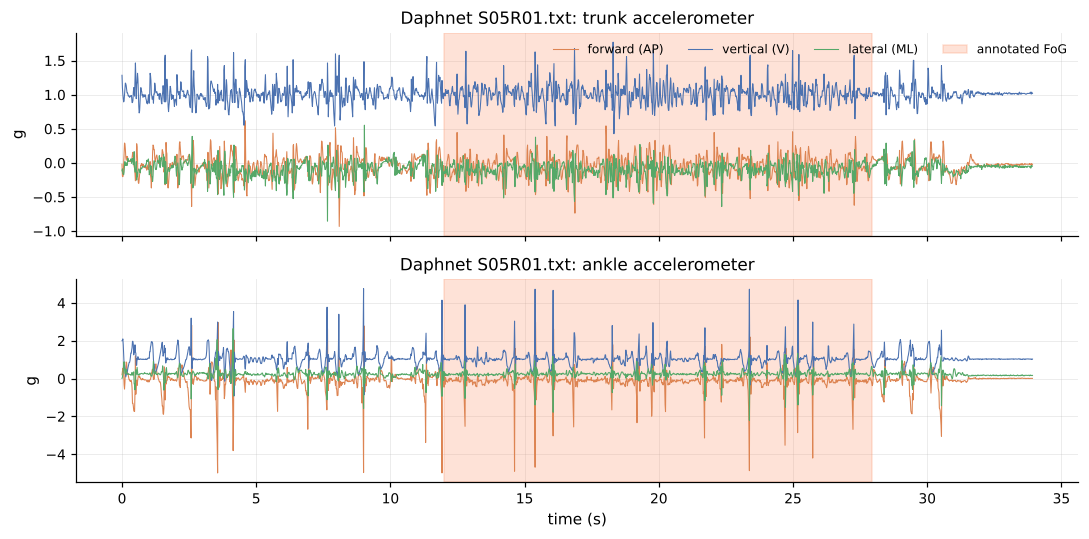

In [8]:
# Daphnet: pick a recording with a long freeze and show trunk next to ankle,
# because the classic FoG "trembling" is mostly an ankle phenomenon.
dap_idx = D.index_daphnet(C.DATA_RAW / "daphnet")
best = (meta_dap.groupby("file").label.sum()).idxmax()
raw = D.parse_daphnet_file(dap_idx.set_index("file").loc[best, "path"])
raw = raw[raw.annotation > 0].reset_index(drop=True)
fog = (raw.annotation == 2).to_numpy()
segs = D.contiguous_segments(fog)
a, b = max(segs, key=lambda s: s[1] - s[0])
lo, hi = max(0, a - 12 * C.FS), min(len(raw), b + 6 * C.FS)
seg = raw.iloc[lo:hi]
t = (np.arange(len(seg))) / C.FS

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, site in zip(axes, ["trunk", "ankle"]):
    for col, c in zip(["fwd", "vert", "lat"], ["#DD8452", "#4C72B0", "#55A868"]):
        ax.plot(t, seg[f"{site}_{col}"] / 1000, lw=0.7, color=c,
                label={"fwd": "forward (AP)", "vert": "vertical (V)", "lat": "lateral (ML)"}[col])
    ax.axvspan((a - lo) / C.FS, (b - lo) / C.FS, color="#FC8D62", alpha=0.25, label="annotated FoG")
    ax.set_ylabel("g")
    ax.set_title(f"Daphnet {best}: {site} accelerometer")
axes[0].legend(ncol=4, frameon=False, loc="upper right", fontsize=8)
axes[1].set_xlabel("time (s)")
fig.tight_layout()
save(fig, "fig05_daphnet_signals")

## 5. Window-level descriptors

* **|a| standard deviation**: movement intensity;
* **peak |a|**: impact strength;
* **freeze index** (Moore et al., 2008): power in the 3-8 Hz "freeze band" over power in the
  0.5-3 Hz locomotion band, here on the trunk AP axis.

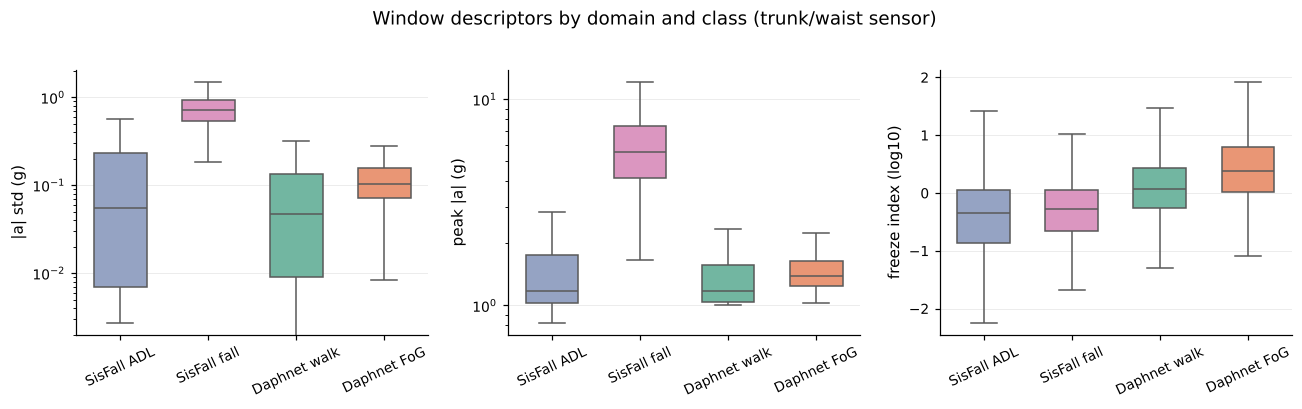

,comparison,descriptor,median A,median B,effect r (rank-biserial),p
0,SisFall ADL vs SisFall fall,|a| std (g),0.0550,0.7144,0.8181,0.0000
1,SisFall ADL vs SisFall fall,peak |a| (g),1.1785,5.5750,0.9429,0.0000
2,SisFall ADL vs SisFall fall,freeze index (log10),-0.3377,-0.2727,0.0860,0.0000
3,Daphnet walk vs Daphnet FoG,|a| std (g),0.0466,0.1042,0.3710,0.0000
4,Daphnet walk vs Daphnet FoG,peak |a| (g),1.1715,1.3895,0.3353,0.0000
5,Daphnet walk vs Daphnet FoG,freeze index (log10),0.0768,0.3812,0.3272,0.0000
6,SisFall ADL vs Daphnet walk,|a| std (g),0.0550,0.0466,-0.0449,0.0000
7,SisFall ADL vs Daphnet walk,peak |a| (g),1.1785,1.1715,0.0057,0.5883
8,SisFall ADL vs Daphnet walk,freeze index (log10),-0.3377,0.0768,0.4217,0.0000


In [9]:
def descriptors(X):
    f, P = signal.welch(X[:, :, 1], fs=C.FS, nperseg=C.WIN, axis=-1)
    loco = P[:, (f >= 0.5) & (f < 3)].sum(1)
    frz = P[:, (f >= 3) & (f <= 8)].sum(1)
    return pd.DataFrame({
        "|a| std (g)": X[:, :, 3].std(1),
        "peak |a| (g)": X[:, :, 3].max(1),
        "freeze index (log10)": np.log10((frz + 1e-9) / (loco + 1e-9)),
    })


desc = []
for name, (X, m) in GROUPS.items():
    idx = np.flatnonzero(m.values)
    idx = rng.choice(idx, min(len(idx), 6000), replace=False)
    d = descriptors(X[idx])
    d["group"] = name
    desc.append(d)
desc = pd.concat(desc, ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col in zip(axes, ["|a| std (g)", "peak |a| (g)", "freeze index (log10)"]):
    sns.boxplot(data=desc, x="group", y=col, hue="group", palette=GCOL, ax=ax, showfliers=False,
                legend=False, width=0.6)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    if col != "freeze index (log10)":
        ax.set_yscale("log")
fig.suptitle("Window descriptors by domain and class (trunk/waist sensor)", y=1.02)
fig.tight_layout()
save(fig, "fig06_window_descriptors")

rows = []
for a_, b_ in [("SisFall ADL", "SisFall fall"), ("Daphnet walk", "Daphnet FoG"), ("SisFall ADL", "Daphnet walk")]:
    for col in ["|a| std (g)", "peak |a| (g)", "freeze index (log10)"]:
        x1 = desc.loc[desc.group == a_, col]
        x2 = desc.loc[desc.group == b_, col]
        u, p = stats.mannwhitneyu(x1, x2)
        rows.append({"comparison": f"{a_} vs {b_}", "descriptor": col,
                     "median A": x1.median(), "median B": x2.median(),
                     "effect r (rank-biserial)": 1 - 2 * u / (len(x1) * len(x2)), "p": p})
tests = pd.DataFrame(rows)
tests.to_csv(C.METRICS / "eda_mannwhitney.csv", index=False)
tests.round(4)

Reading the table and the boxplots together:

* a fall window is an order of magnitude more energetic than any ADL window, with a median
  peak of several g;
* at the trunk, FoG differs from normal Parkinsonian walking far less: the peak rises by about
  0.2 g, the |a| variability roughly doubles and the freeze index goes up, all with moderate
  effect sizes;
* healthy ADL and Parkinsonian walking have almost identical amplitudes but different spectral
  content (higher freeze index in Daphnet).

For a detector that learned "event = violent multi-g transient", FoG is at most a slightly
more agitated walking window, far from anything it was trained to flag. The positive classes
of the two domains overlap very little: this is a change of the event itself (concept
shift), not only a change of the population.

## 6. Spectra

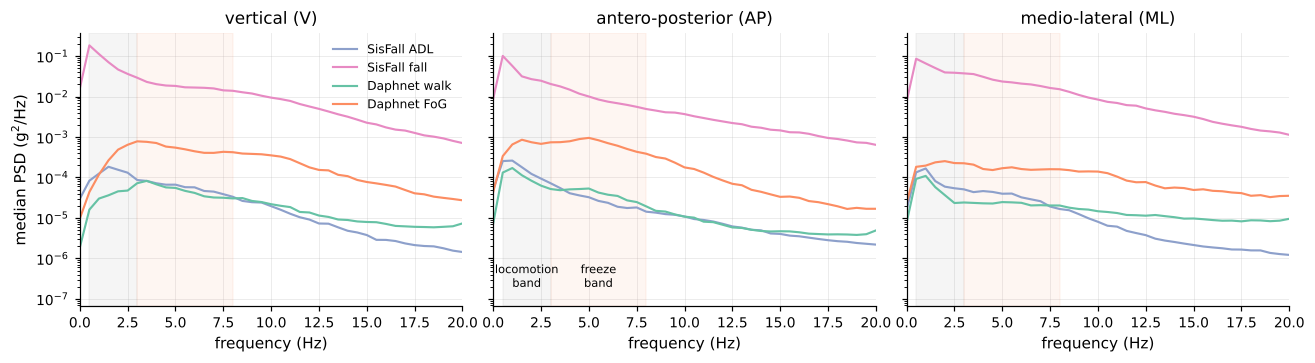

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, ch, name in zip(axes, [0, 1, 2], ["vertical (V)", "antero-posterior (AP)", "medio-lateral (ML)"]):
    for g, (X, m) in GROUPS.items():
        idx = np.flatnonzero(m.values)
        idx = rng.choice(idx, min(len(idx), 4000), replace=False)
        x = X[idx, :, ch] - X[idx, :, ch].mean(1, keepdims=True)
        f, P = signal.welch(x, fs=C.FS, nperseg=C.WIN, axis=-1)
        Pm = np.median(P, axis=0)
        ax.semilogy(f, Pm, color=GCOL[g], lw=1.4, label=g)
    ax.axvspan(0.5, 3, color="grey", alpha=0.08)
    ax.axvspan(3, 8, color="#FC8D62", alpha=0.08)
    ax.set_xlim(0, 20)
    ax.set_xlabel("frequency (Hz)")
    ax.set_title(name)
axes[0].set_ylabel("median PSD (g$^2$/Hz)")
axes[0].legend(frameon=False, fontsize=8)
axes[1].text(1.75, axes[1].get_ylim()[0] * 3, "locomotion\nband", ha="center", fontsize=7.5)
axes[1].text(5.5, axes[1].get_ylim()[0] * 3, "freeze\nband", ha="center", fontsize=7.5)
fig.tight_layout()
save(fig, "fig07_power_spectra")

## 7. Amplitude distributions before and after scaling

Left: raw g. Middle: both domains scaled with SisFall training statistics (what a naive
deployment would do). Right: each domain scaled with its own unlabeled statistics.
Daphnet values are stored with a resolution of about 10 mg, against 3.9 mg for the SisFall
ADXL345, so a coarse binning is used to avoid comb artefacts in the histograms.

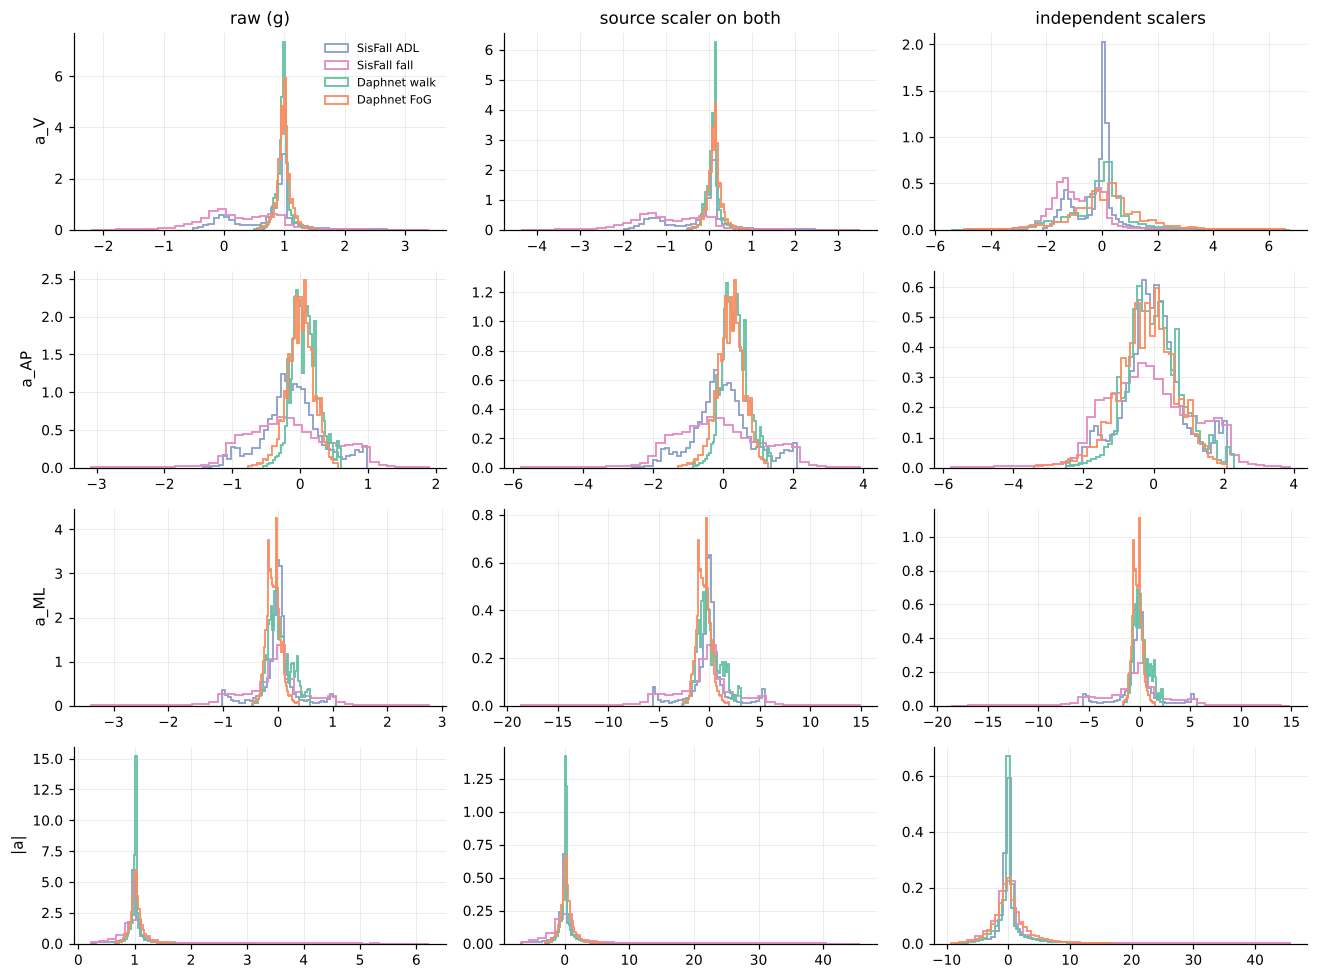

In [11]:
src = RobustScaler()
src.center_, src.scale_ = (np.array(scalers["source"][k], dtype=np.float32) for k in ("center", "scale"))
tgt = RobustScaler()
tgt.center_, tgt.scale_ = (np.array(scalers["target"][k], dtype=np.float32) for k in ("center", "scale"))

fig, axes = plt.subplots(4, 3, figsize=(12, 9))
for r_, ch in enumerate(C.CHANNELS):
    for c_, mode in enumerate(["raw (g)", "source scaler on both", "independent scalers"]):
        ax = axes[r_, c_]
        for g, (X, m) in GROUPS.items():
            idx = np.flatnonzero(m.values)
            idx = rng.choice(idx, min(len(idx), 3000), replace=False)
            x = X[idx]
            if mode == "source scaler on both":
                x = src.transform(x)
            elif mode == "independent scalers":
                x = (src if g.startswith("SisFall") else tgt).transform(x)
            v = x[:, :, r_].ravel()
            lo_, hi_ = np.percentile(v, [0.5, 99.5])
            ax.hist(v, bins=40, range=(lo_, hi_), density=True, histtype="step", lw=1.2,
                    color=GCOL[g], label=g)
        if r_ == 0:
            ax.set_title(mode)
        if c_ == 0:
            ax.set_ylabel(ch)
axes[0, 0].legend(frameon=False, fontsize=7.5)
fig.tight_layout()
save(fig, "fig08_amplitude_distributions")

## 8. Channel coupling

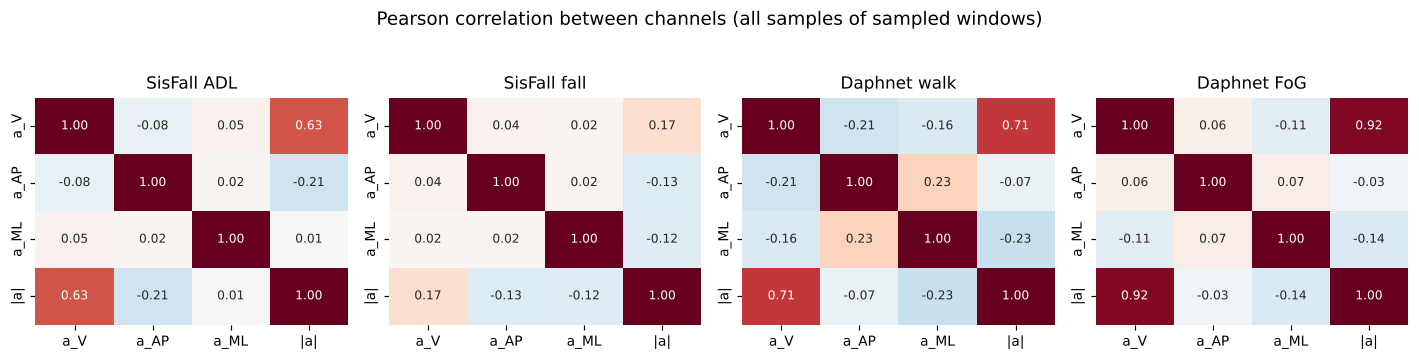

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1))
for ax, (g, (X, m)) in zip(axes, GROUPS.items()):
    idx = np.flatnonzero(m.values)
    idx = rng.choice(idx, min(len(idx), 3000), replace=False)
    flat = X[idx].reshape(-1, 4)
    sns.heatmap(np.corrcoef(flat.T), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r",
                xticklabels=C.CHANNELS, yticklabels=C.CHANNELS, ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set_title(g)
fig.suptitle("Pearson correlation between channels (all samples of sampled windows)", y=1.04)
fig.tight_layout()
save(fig, "fig09_channel_correlation")

## 9. Low-dimensional view of the raw windows

A quick t-SNE on hand-crafted window statistics shows how the four groups sit relative to each
other before any network is involved.

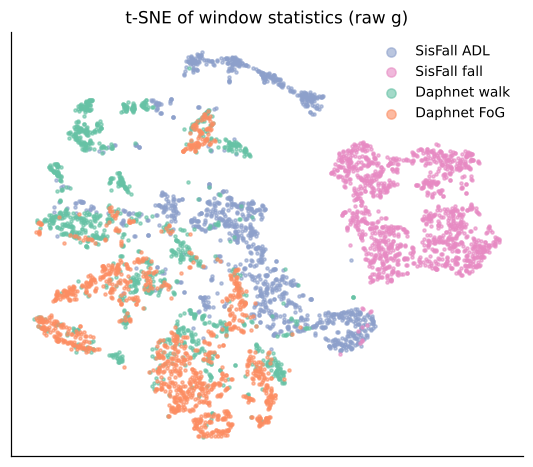

In [13]:
from sklearn.manifold import TSNE


def stats_feats(X):
    q = np.percentile(X, [5, 50, 95], axis=1).transpose(1, 0, 2).reshape(len(X), -1)
    return np.hstack([X.mean(1), X.std(1), q, descriptors(X).values])


feat, lab = [], []
for g, (X, m) in GROUPS.items():
    idx = np.flatnonzero(m.values)
    idx = rng.choice(idx, min(len(idx), 1200), replace=False)
    feat.append(stats_feats(X[idx]))
    lab += [g] * len(idx)
F = np.vstack(feat)
F = (F - F.mean(0)) / (F.std(0) + 1e-6)
Z = TSNE(n_components=2, perplexity=40, init="pca", random_state=0).fit_transform(F)
fig, ax = plt.subplots(figsize=(6, 5))
lab = np.array(lab)
for g in GROUPS:
    ax.scatter(*Z[lab == g].T, s=4, alpha=0.6, color=GCOL[g], label=g)
ax.legend(markerscale=3, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("t-SNE of window statistics (raw g)")
save(fig, "fig10_tsne_raw_features")

In [14]:
print(sorted(p.name for p in C.FIGURES.glob("fig*.png")))

['fig01_pipeline.png', 'fig02_class_balance.png', 'fig03_axis_identification.png', 'fig04_sisfall_signals.png', 'fig05_daphnet_signals.png', 'fig06_window_descriptors.png', 'fig07_power_spectra.png', 'fig08_amplitude_distributions.png', 'fig09_channel_correlation.png', 'fig10_tsne_raw_features.png', 'fig11_hparam_search.png', 'fig12_learning_curves.png', 'fig13_normalisation_ablation.png', 'fig14_roc_pr_curves.png', 'fig15_confusion_matrices.png', 'fig16_metric_comparison.png', 'fig17_daphnet_score_distributions.png', 'fig18_per_patient_auroc.png', 'fig19_target_adaptation.png', 'fig20_embedding_tsne.png', 'fig21_shift_decomposition.png', 'fig22_overview_auroc.png']
